<a href="https://colab.research.google.com/github/HamedKhosravi99/TrainYourAgent/blob/main/notebooks/04_llm_tool_use_grpo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**TrainYourAgent** · [Ch 1 · Q-learning](https://colab.research.google.com/github/HamedKhosravi99/TrainYourAgent/blob/main/notebooks/01_q_learning_tool_agent.ipynb) → [Ch 2 · REINFORCE](https://colab.research.google.com/github/HamedKhosravi99/TrainYourAgent/blob/main/notebooks/02_policy_gradient_reinforce.ipynb) → [Ch 3 · GRPO](https://colab.research.google.com/github/HamedKhosravi99/TrainYourAgent/blob/main/notebooks/03_grpo_from_scratch.ipynb) → **📍 Ch 4 · LLM + tools**

# 🛒 Chapter 4 · Agentic RL for a real LLM: teach Qwen to use tools with GRPO

### From toy buttons to a real language model that looks things up, calculates, and answers.

**The mission:** turn a small open LLM, **Qwen2.5-0.5B-Instruct**, into a **shop assistant** with two tools:

- 🔎 `lookup`: finds the price of an item. The prices are **made up**, so the model *cannot* know them.
- 🧮 `calculator`: does exact arithmetic, which small models are bad at.

A question like *"How much do 37 notebooks and 12 rulers cost in total?"* needs a real **plan**: look up both prices → calculate → answer. That's the *observe → act → observe → act* loop from Chapter 1, but now the agent is a real LLM writing real text.

We train it with **GRPO**, written from scratch like in Chapter 3. **Reward = 1 only if the final number is exactly right.** We never reward tool use directly. The model has to discover that using the tools *well* is what pays off.

⚡ **Runtime:** a free Colab **T4 GPU** (*Runtime → Change runtime type → T4 GPU*). Training takes roughly 15–30 minutes. It also runs on an Apple-silicon Mac (slower), and on CPU only with a lot of patience.

📝 *The outputs saved in this notebook come from a run on an Apple M4 laptop (`mps`). Your numbers will differ a little because sampling is random, but the story should be the same.*

### What's new compared to Chapter 3?

| Chapter 3 (toy) | Chapter 4 (this notebook) |
|:--|:--|
| One word = one token, 34-word vocabulary | A real tokenizer with ~150,000 tokens |
| `TinyPolicy`, ~1,000 numbers | Qwen2.5-0.5B, ~500 million numbers |
| Press a button | Write text, including **tool calls** like `<lookup>ruler</lookup>` |
| The world returns a result | The tool's output is **pasted into the text**, and the model keeps writing |
| Train on every decision | Train only on tokens the **model** wrote (a **loss mask**) |
| Update all the numbers | Update small **LoRA** adapters (~2% of the model) |

## 0 · Setup ⚙️

Colab already has PyTorch and 🤗 `transformers`. This cell just makes sure `transformers` is recent enough.

In [1]:
%pip install -q "transformers>=4.56"

In [2]:
import ast
import math
import operator
import random
import re
import time

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer

random.seed(0)
torch.manual_seed(0)

/private/tmp/claude-504/-Users-hkhosravi7-Documents-GitHub-Codes/f31ee202-8b9c-4839-bea3-d5b8afdf0b9b/scratchpad/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
def pick_device():
    if torch.cuda.is_available():
        bf16 = torch.cuda.is_bf16_supported(including_emulation=False)
        return "cuda", (torch.bfloat16 if bf16 else torch.float32)
    if torch.backends.mps.is_available():
        return "mps", torch.float32
    return "cpu", torch.float32


device, dtype = pick_device()
print("Running on:", device, "| weights stored as:", dtype)
if device == "cpu":
    print("⚠️ No GPU found. On Colab: Runtime → Change runtime type → T4 GPU (training on CPU is very slow).")

Running on: mps | weights stored as: torch.float32


## 1 · The shop and its questions 🏪

Here is the store's price list. The model has never seen it, and the prices are invented, so the only way to get them right is to **look them up**.

In [4]:
PRICES = {"notebook": 3.75, "pencil": 0.45, "backpack": 27.90, "eraser": 0.85, "marker": 1.65,
          "ruler": 2.30, "stapler": 8.40, "folder": 0.95, "highlighter": 1.35, "glue stick": 1.15,
          "paint set": 9.80, "sticker pack": 2.05}

There are four kinds of questions. Some need only the calculator, and some need one or two lookups first:

In [5]:
WORD_PROBLEMS = [
    ("A farmer plants {a} rows of trees with {b} trees in each row. "
     "How many trees does the farmer plant?", lambda a, b, c: a * b),
    ("A factory makes {a} toys every day. How many toys does it make in {b} days?",
     lambda a, b, c: a * b),
    ("A school buys {a} boxes of pencils. Each box holds {b} pencils. "
     "The school gives away {c} pencils. How many pencils are left?", lambda a, b, c: a * b - c),
    ("A train travels {a} km every day for {b} days, and then {c} km more. "
     "How far does it travel in total?", lambda a, b, c: a * b + c),
    ("A library has {a} shelves with {b} books on each shelf, plus {c} books in storage. "
     "How many books does it have?", lambda a, b, c: a * b + c),
    ("A bakery sells {a} cakes for {b} dollars each and spends {c} dollars on flour. "
     "How much money is left?", lambda a, b, c: a * b - c),
]


TASK_KINDS = ("math", "shop1", "shop2", "budget")


def make_task(rng, kind=None):
    """Return {"question", "answer", "kind"}. Kinds:
    math   - word problem, needs the calculator          ("A farmer plants 347 rows of ...")
    shop1  - one price lookup + calculator               ("How much do 37 notebooks cost?")
    shop2  - two price lookups + calculator              ("... 37 notebooks and 12 rulers ...")
    budget - lookup + calculator, then subtract          ("I have 300 dollars and buy ...")
    """
    kind = kind or rng.choice(TASK_KINDS)
    if kind == "math":
        text, solve = rng.choice(WORD_PROBLEMS)
        a, b = rng.randint(101, 999), rng.randint(12, 99)
        c = rng.randint(100, a * b - 1)
        return {"question": text.format(a=a, b=b, c=c), "answer": solve(a, b, c), "kind": kind}
    item1, item2 = rng.sample(sorted(PRICES), 2)
    n1, n2 = rng.randint(12, 99), rng.randint(12, 99)
    cost1, cost2 = n1 * PRICES[item1], n2 * PRICES[item2]
    if kind == "shop1":
        return {"question": f"How much do {n1} {item1}s cost?", "answer": round(cost1, 2), "kind": kind}
    if kind == "shop2":
        return {"question": f"How much do {n1} {item1}s and {n2} {item2}s cost in total?",
                "answer": round(cost1 + cost2, 2), "kind": kind}
    budget = rng.randint(int(cost1) + 5, int(cost1) + 300)
    return {"question": f"I have {budget} dollars and buy {n1} {item1}s. How much money do I have left?",
            "answer": round(budget - cost1, 2), "kind": kind}

In [6]:
rng = random.Random(0)
for kind in TASK_KINDS:
    task = make_task(rng, kind)
    print(f"[{kind:6}] {task['question']}\n          → correct answer: {task['answer']}\n")

[math  ] A train travels 877 km every day for 65 days, and then 2753 km more. How far does it travel in total?
          → correct answer: 59758

[shop1 ] How much do 74 highlighters cost?
          → correct answer: 99.9

[shop2 ] How much do 57 highlighters and 86 paint sets cost in total?
          → correct answer: 919.75

[budget] I have 109 dollars and buy 29 glue sticks. How much money do I have left?
          → correct answer: 75.65



## 2 · The tools 🧰

**The calculator** never uses Python's `eval` (which would let the model run any code!). It parses the expression and only allows numbers, `+ − × ÷` and parentheses. **The lookup** reads the price list and forgives plurals and capital letters.

In [7]:
_OPS = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul,
        ast.Div: operator.truediv, ast.FloorDiv: operator.floordiv, ast.Mod: operator.mod,
        ast.USub: operator.neg, ast.UAdd: operator.pos}


def calculator(expression):
    """Evaluate + - * / // % and parentheses on numbers. Anything else returns "error"."""
    def evaluate(node):
        if isinstance(node, ast.Constant) and type(node.value) in (int, float):
            return node.value
        if isinstance(node, ast.BinOp) and type(node.op) in _OPS:
            return _OPS[type(node.op)](evaluate(node.left), evaluate(node.right))
        if isinstance(node, ast.UnaryOp) and type(node.op) in _OPS:
            return _OPS[type(node.op)](evaluate(node.operand))
        raise ValueError("unsupported expression")

    try:
        cleaned = " ".join(expression.replace(",", "").replace("×", "*").replace("÷", "/").split())
        value = evaluate(ast.parse(cleaned, mode="eval").body)
        return str(int(value)) if float(value).is_integer() else str(round(value, 4))
    except Exception:
        return "error"


def lookup(item):
    """Price of an item in dollars ("notebooks" and "Notebook" both work)."""
    name = " ".join(item.lower().strip(" .?!").split())
    for candidate in (name, name[:-1] if name.endswith("s") else name):
        if candidate in PRICES:
            return f"{PRICES[candidate]:.2f}"
    return "unknown item"

In [8]:
print(calculator("37 * 3.75 + 12 * 2.30"))
print(calculator("__import__('os').system('rm -rf /')"))   # not allowed → "error"
print(lookup("Notebooks"), lookup("unicorn"))

166.35
error
3.75 unknown item


**How does the model call a tool?** It writes a tag such as `<lookup>ruler</lookup>` and stops. We find the tag with a regular expression, run the tool, and paste the result back as `<result>2.30</result>`.

In [9]:
TOOLS = {"calculator": calculator, "lookup": lookup}


TOOL_CALL = re.compile(r"<(calculator|lookup)>(.*?)</\1>", re.S)


STOP_STRINGS = ["</calculator>", "</lookup>", "</answer>"]

## 3 · Tell the model about its tools 📜

An LLM only knows what's in its text. This **system prompt** is the whole "manual" for the tools:

In [10]:
SYSTEM_PROMPT = (
    "You are a shop assistant with two tools.\n"
    "- To find the price of an item in dollars, write the item name inside <lookup></lookup> tags, "
    "for example <lookup>pencil</lookup>, and then stop.\n"
    "- To calculate, write an arithmetic expression inside <calculator></calculator> tags, "
    "for example <calculator>12 * (3 + 4)</calculator>, and then stop.\n"
    "Each tool result is returned to you inside <result></result> tags. You can use the tools several times.\n"
    "When you know the final answer, write the number inside <answer></answer> tags, "
    "for example <answer>84</answer>."
)

print(SYSTEM_PROMPT)

You are a shop assistant with two tools.
- To find the price of an item in dollars, write the item name inside <lookup></lookup> tags, for example <lookup>pencil</lookup>, and then stop.
- To calculate, write an arithmetic expression inside <calculator></calculator> tags, for example <calculator>12 * (3 + 4)</calculator>, and then stop.
Each tool result is returned to you inside <result></result> tags. You can use the tools several times.
When you know the final answer, write the number inside <answer></answer> tags, for example <answer>84</answer>.


## 4 · The reward 🏆

Simple and **verifiable**: find the last `<answer>...</answer>` and compare it with the true number. **1** if it's right (to the cent), **0** otherwise. There are no points for style and no points for using tools.

In [11]:
def parse_answer(text):
    found = re.findall(r"<answer>(.*?)</answer>", text, re.S)
    if not found:
        return None
    try:
        return float(found[-1].replace(",", "").replace("$", "").strip())
    except ValueError:
        return None


def reward_fn(text, answer):
    got = parse_answer(text)
    return 1.0 if got is not None and abs(got - answer) < 0.01 else 0.0

In [12]:
print(reward_fn("<lookup>ruler</lookup> ... <answer>27.60</answer>", 27.6))   # right → 1
print(reward_fn("<answer>2.30</answer>", 27.6))                              # wrong → 0
print(reward_fn("The total is 27.60 dollars.", 27.6))                        # no answer tag → 0

1.0
0.0
0.0


💡 **Why not reward tool use too?** It's tempting, but RL agents are experts at finding loopholes. If calling a tool earned points, the agent would learn to call tools *a lot*, whether or not they help. Rewarding only the **outcome** keeps the agent honest.

## 5 · Meet the LLM 🤖

We load **Qwen2.5-0.5B-Instruct** (about 1 GB). It's small enough for a free GPU, and it's an *instruct* model, so it already follows instructions somewhat.

In [13]:
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"   # 👈 any small chat model with a chat template works

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=dtype).to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.0f} million")

W1019 22:26:36.546000 48236 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/290 [00:00<02:14,  2.15it/s]

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 609.93it/s]

Parameters: 494 million


### What the LLM *really* sees 👀

A chat model doesn't see "messages". It sees one long string with special tokens marking who is speaking. `build_prompt` turns our system prompt + question into token ids:

In [14]:
def build_prompt(tokenizer, question):
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": question}]
    text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    return tokenizer(text, add_special_tokens=False).input_ids

In [15]:
ids = build_prompt(tokenizer, "How much do 37 notebooks cost?")
print(f"{len(ids)} tokens:\n")
print(tokenizer.decode(ids))

154 tokens:

<|im_start|>system
You are a shop assistant with two tools.
- To find the price of an item in dollars, write the item name inside <lookup></lookup> tags, for example <lookup>pencil</lookup>, and then stop.
- To calculate, write an arithmetic expression inside <calculator></calculator> tags, for example <calculator>12 * (3 + 4)</calculator>, and then stop.
Each tool result is returned to you inside <result></result> tags. You can use the tools several times.
When you know the final answer, write the number inside <answer></answer> tags, for example <answer>84</answer>.<|im_end|>
<|im_start|>user
How much do 37 notebooks cost?<|im_end|>
<|im_start|>assistant



## 6 · The agent loop: rollouts with real tool calls 🔁

This is the heart of **agentic** RL. One episode (a *rollout*) goes like this:

1. The model writes until it closes a tool tag (`</lookup>` or `</calculator>`) or gives an answer.
2. If it called a tool, **we run the tool** and paste `<result>...</result>` into the text.
3. The model continues writing, now able to *see* the result. Repeat, up to 4 tool calls.

The whole episode is one long token sequence. Some of it was written by the **model** and some by the **tool**. We record which is which in a **loss mask**: `1` = the model wrote this token, `0` = the tool wrote it.

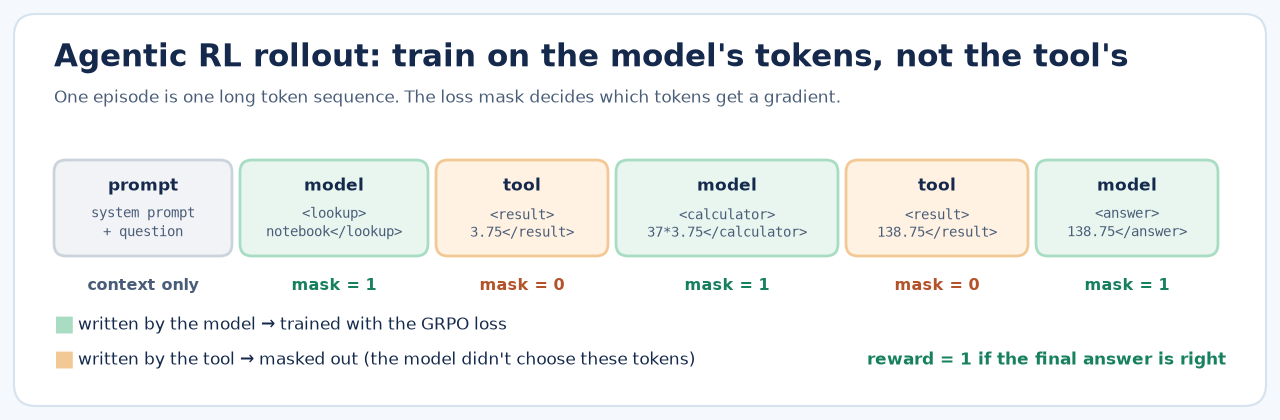

Why does the mask matter? The GRPO update makes the model's *own choices* more or less likely. The tool's output wasn't the model's choice. Training on it would teach the model to *hallucinate* tool results instead of calling the tool. [Search-R1](https://arxiv.org/abs/2503.09516) and [ReTool](https://arxiv.org/abs/2504.11536) use the same trick.

`rollout` runs many episodes **in parallel** (a batch). The code is longer than in Chapter 3, but every line maps to the steps above:

In [16]:
def left_pad(sequences, pad_id):
    width = max(len(s) for s in sequences)
    ids = torch.full((len(sequences), width), pad_id, dtype=torch.long)
    attention = torch.zeros((len(sequences), width), dtype=torch.long)
    for row, seq in enumerate(sequences):
        ids[row, width - len(seq):] = torch.tensor(seq)
        attention[row, width - len(seq):] = 1
    return ids, attention


@torch.no_grad()
def rollout(model, tokenizer, questions, temperature=0.8, greedy=False,
            max_tool_calls=4, max_new_tokens=128):
    device = next(model.parameters()).device
    pad = tokenizer.pad_token_id
    prompt_ids = [build_prompt(tokenizer, q) for q in questions]
    completion_ids = [[] for _ in questions]
    loss_mask = [[] for _ in questions]
    tool_calls = [[] for _ in questions]   # names of the tools each episode used
    sampling = (dict(do_sample=False) if greedy else
                dict(do_sample=True, temperature=temperature, top_p=1.0, top_k=0))

    active = list(range(len(questions)))
    for turn in range(max_tool_calls + 1):
        if not active:
            break
        ids, attention = left_pad([prompt_ids[i] + completion_ids[i] for i in active], pad)
        output = model.generate(
            input_ids=ids.to(device), attention_mask=attention.to(device),
            max_new_tokens=max_new_tokens, stop_strings=STOP_STRINGS,
            tokenizer=tokenizer, pad_token_id=pad, repetition_penalty=1.0, **sampling)
        still_active = []
        for row, i in enumerate(active):
            new_tokens = output[row, ids.shape[1]:].tolist()
            while new_tokens and new_tokens[-1] == pad:      # drop padding after a finished row
                new_tokens.pop()
            completion_ids[i] += new_tokens
            loss_mask[i] += [1] * len(new_tokens)          # model-written tokens: train on them
            text = tokenizer.decode(new_tokens)
            calls = TOOL_CALL.findall(text)
            if calls and "</answer>" not in text and turn < max_tool_calls:
                name, argument = calls[-1]
                result = TOOLS[name](argument)
                tool_tokens = tokenizer(f"\n<result>{result}</result>\n",
                                        add_special_tokens=False).input_ids
                completion_ids[i] += tool_tokens
                loss_mask[i] += [0] * len(tool_tokens)     # tool-written tokens: don't train
                tool_calls[i].append(name)
                still_active.append(i)
        active = still_active

    return {"prompt_ids": prompt_ids, "completion_ids": completion_ids, "loss_mask": loss_mask,
            "texts": [tokenizer.decode(c) for c in completion_ids], "tool_calls": tool_calls}

### Watch the untrained model work 🍿

One question of each kind. Watch what it does with the tool results:

In [17]:
demo_tasks = [make_task(random.Random(7), kind) for kind in TASK_KINDS]
demo = rollout(model, tokenizer, [t["question"] for t in demo_tasks], greedy=True)
for task, text in zip(demo_tasks, demo["texts"]):
    verdict = "✅" if reward_fn(text, task["answer"]) else "❌"
    print(f"Q: {task['question']}  (correct: {task['answer']}) {verdict}\n{text.strip()}\n" + "-" * 80)

Q: A school buys 255 boxes of pencils. Each box holds 62 pencils. The school gives away 10764 pencils. How many pencils are left?  (correct: 5046) ✅
<calculator>255 * 62 - 10764</calculator>
<result>5046</result>
<answer>5046</answer>
--------------------------------------------------------------------------------
Q: How much do 62 markers cost?  (correct: 102.3) ❌
<lookup>markers</lookup>
<result>1.65</result>
<answer>1.65</answer>
--------------------------------------------------------------------------------
Q: How much do 62 markers and 95 folders cost in total?  (correct: 192.55) ❌
<lookup>markers</lookup>
<result>1.65</result>
<lookup>folders</lookup>

<result>0.95</result>
<calculator>12 * (3 + 4)</calculator>

<result>84</result>
<answer>84</answer>
--------------------------------------------------------------------------------
Q: I have 131 dollars and buy 62 markers. How much money do I have left?  (correct: 28.7) ❌
<lookup>markers</lookup>
<result>1.65</result>
<answer>1.6

In our runs, the base model usually **looks up the price correctly**, then answers with **the price itself** (or the sum of two prices) and **forgets to multiply by the quantity**. (In our run it even copied the example calculation `12 * (3 + 4)` straight out of the instructions!) It knows the tools exist, but it doesn't know how to *plan* with them. That's what RL will fix.

## 7 · Before training: how good is it? 📏

We test on **64 held-out questions** that are never used for training, with greedy decoding (no randomness).

In [18]:
def evaluate(model, tokenizer, tasks):
    """Greedy decoding on held-out tasks: overall accuracy and accuracy per task kind."""
    model.eval()
    out = rollout(model, tokenizer, [t["question"] for t in tasks], greedy=True)
    rewards = [reward_fn(text, t["answer"]) for text, t in zip(out["texts"], tasks)]
    per_kind, calls_per_kind = {}, {}
    for kind in TASK_KINDS:
        rows = [(r, len(c)) for r, c, t in zip(rewards, out["tool_calls"], tasks) if t["kind"] == kind]
        if rows:
            per_kind[kind] = sum(r for r, _ in rows) / len(rows)
            calls_per_kind[kind] = sum(n for _, n in rows) / len(rows)
    return {"accuracy": sum(rewards) / len(rewards), "per_kind": per_kind,
            "calls_per_kind": calls_per_kind, "texts": out["texts"], "tool_calls": out["tool_calls"]}

In [19]:
eval_tasks = [make_task(random.Random(10_000 + i)) for i in range(64)]   # held-out, never trained on
start = time.time()
before = evaluate(model, tokenizer, eval_tasks)
print(f"Before training: {before['accuracy']:.0%} correct  ({time.time() - start:.0f}s)")
for kind, acc in before["per_kind"].items():
    print(f"  {kind:6} {acc:.0%}")

Before training: 16% correct  (17s)
  math   64%
  shop1  6%
  shop2  13%
  budget 0%


## 8 · LoRA from scratch: train 2% of the model 🩹

Updating all 500 million numbers needs a lot of GPU memory (the optimizer keeps two extra copies of everything). **LoRA** freezes the model and adds a small trainable **patch** next to each big weight matrix:

```
output = W·x  +  (B·A)·x × scale        W: frozen (896×896)   A: 16×896   B: 896×16
```

`B` starts at zero, so at first the patch does nothing and the model is unchanged. And for RL, LoRA is enough: [recent experiments](https://thinkingmachines.ai/blog/lora/) found that even tiny LoRA adapters match full fine-tuning for policy-gradient training, because each episode carries only a little information.

**Bonus:** switch the patches off and you get the **original model** back. That's a free *reference model* for the KL leash from Chapter 3, with no second copy needed.

In [20]:
class LoRALinear(nn.Module):
    def __init__(self, base, rank=16, alpha=32):
        super().__init__()
        self.base, self.scale, self.enabled = base, alpha / rank, True
        self.A = nn.Parameter(torch.empty(rank, base.in_features, device=base.weight.device))
        self.B = nn.Parameter(torch.zeros(base.out_features, rank, device=base.weight.device))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))  # B = 0, so the patch starts as a no-op

    def forward(self, x):
        out = self.base(x)
        if self.enabled:
            out = out + ((x.to(self.A.dtype) @ self.A.T) @ self.B.T * self.scale).to(out.dtype)
        return out


LORA_TARGETS = ("q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj")


def add_lora(model, rank=16, alpha=32):
    for p in model.parameters():
        p.requires_grad_(False)
    for module in list(model.modules()):
        for name, child in list(module.named_children()):
            if name in LORA_TARGETS and isinstance(child, nn.Linear):
                setattr(module, name, LoRALinear(child, rank, alpha))
    return [p for p in model.parameters() if p.requires_grad]


def set_lora(model, enabled):
    for m in model.modules():
        if isinstance(m, LoRALinear):
            m.enabled = enabled

In [21]:
model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})  # saves memory
lora_params = add_lora(model, rank=16, alpha=32)
trainable = sum(p.numel() for p in lora_params)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable: {trainable / 1e6:.1f}M of {total / 1e6:.0f}M numbers ({trainable / total:.1%})")

Trainable: 8.8M of 503M numbers (1.7%)


## 9 · The GRPO loss, now with a loss mask ✂️

The same three ingredients as Chapter 3:

1. **Group advantages:** 8 answers per question, each compared with its siblings.
2. **Log-probs:** `token_logprobs` asks the model "how likely was each token you wrote?" in one forward pass. Here one decision = one token.
3. **The clipped objective**, averaged over every **trained** token (`mask = 1`) in the batch. The KL leash is optional: `beta=0` turns it off, as in many recent recipes.

In [22]:
def group_advantages(rewards, group_size):
    r = torch.tensor(rewards, dtype=torch.float32).view(-1, group_size)
    return ((r - r.mean(1, keepdim=True)) / (r.std(1, keepdim=True) + 1e-4)).view(-1)


def right_pad(prompt_ids, completion_ids, loss_mask, pad_id):
    """Stack prompt+completion into one batch. mask[t] = 1 where token t should be trained."""
    seqs = [p + c for p, c in zip(prompt_ids, completion_ids)]
    masks = [[0] * len(p) + m for p, m in zip(prompt_ids, loss_mask)]
    width = max(len(s) for s in seqs)
    ids = torch.tensor([s + [pad_id] * (width - len(s)) for s in seqs])
    attention = torch.tensor([[1] * len(s) + [0] * (width - len(s)) for s in seqs])
    mask = torch.tensor([m + [0] * (width - len(m)) for m in masks], dtype=torch.float32)
    return ids, attention, mask


def token_logprobs(model, ids, attention, temperature):
    """log pi(token_t | tokens_<t) for every position t >= 1 (shape: batch x (len-1))."""
    logits = model(input_ids=ids, attention_mask=attention, use_cache=False).logits[:, :-1]
    logits = logits.float() / temperature
    return torch.gather(logits.log_softmax(-1), 2, ids[:, 1:, None]).squeeze(-1)


def grpo_loss(logp, old_logp, advantages, mask, n_tokens, clip=0.2, ref_logp=None, beta=0.0):
    ratio = torch.exp(logp - old_logp)
    A = advantages[:, None]
    per_token = -torch.min(ratio * A, ratio.clamp(1 - clip, 1 + clip) * A)
    if ref_logp is not None and beta > 0:
        diff = ref_logp - logp
        per_token = per_token + beta * (torch.exp(diff) - diff - 1)
    return (per_token * mask).sum() / n_tokens   # average over every trained token in the batch

### See the mask on a real rollout 🔬

Tokens in `[[double brackets]]` were written by the tool and will **not** be trained:

In [23]:
text = ""
for token, m in zip(demo["completion_ids"][1], demo["loss_mask"][1]):
    piece = tokenizer.decode([token])
    text += piece if m else f"[[{piece}]]"
print(text.replace("]][[", ""))

<lookup>markers</lookup>[[
<result>1.65</result>
]]<answer>1.65</answer>


## 10 · One GRPO step 🔧

Sample a group of answers for each question → score them → compute advantages → skip groups where every answer got the same reward (no signal) → one masked, clipped update.

In [24]:
def free_cached_memory(device):
    """Apple-silicon GPUs keep freed memory cached; hand it back between generation and training."""
    if device.type == "mps":
        torch.mps.empty_cache()


def grpo_step(model, tokenizer, optimizer, params, tasks, group_size, temperature,
              micro_batch=4, clip=0.2, beta=0.0, tool_cost=0.0, max_grad_norm=1.0):
    device = next(model.parameters()).device
    questions = [t["question"] for t in tasks for _ in range(group_size)]
    answers = [t["answer"] for t in tasks for _ in range(group_size)]

    model.eval()
    batch = rollout(model, tokenizer, questions, temperature=temperature)
    free_cached_memory(device)
    rewards = [reward_fn(text, a) - tool_cost * len(calls)       # optional price per tool call
               for text, a, calls in zip(batch["texts"], answers, batch["tool_calls"])]
    advantages = group_advantages(rewards, group_size)
    keep = [i for i in range(len(questions)) if advantages[i].abs() > 1e-6]  # skip no-signal groups

    model.train()
    n_tokens = max(1, sum(sum(batch["loss_mask"][i]) for i in keep))
    for start in range(0, len(keep), micro_batch):
        idx = keep[start:start + micro_batch]
        ids, attention, mask = right_pad([batch["prompt_ids"][i] for i in idx],
                                         [batch["completion_ids"][i] for i in idx],
                                         [batch["loss_mask"][i] for i in idx], tokenizer.pad_token_id)
        ids, attention, mask = ids.to(device), attention.to(device), mask[:, 1:].to(device)
        ref_logp = None
        if beta > 0:
            with torch.no_grad():
                set_lora(model, False)
                ref_logp = token_logprobs(model, ids, attention, temperature)
                set_lora(model, True)
        logp = token_logprobs(model, ids, attention, temperature)
        # One update per batch, so the "old" policy is the current one (ratio = 1 at this point).
        loss = grpo_loss(logp, logp.detach(), advantages[idx].to(device), mask, n_tokens,
                         clip, ref_logp, beta)
        loss.backward()
    grad_norm = torch.nn.utils.clip_grad_norm_(params, max_grad_norm).item() if keep else 0.0
    optimizer.step()
    optimizer.zero_grad(set_to_none=True)
    free_cached_memory(device)
    return {"reward": sum(rewards) / len(rewards),
            "lookup_use": sum("lookup" in c for c in batch["tool_calls"]) / len(questions),
            "calculator_use": sum("calculator" in c for c in batch["tool_calls"]) / len(questions),
            "trained_on": len(keep), "grad_norm": grad_norm, "example": batch["texts"][0]}

## 11 · Train! 🎯

Each step: **8 questions × 8 attempts = 64 episodes**, then one update. Watch the reward climb and the tool use change.

On a T4, each step takes roughly 30–60 seconds. Early steps are the slowest because there's more to learn from.

In [25]:
STEPS = 25               # 👈 more steps = more practice
QUESTIONS_PER_STEP = 8
GROUP_SIZE = 8           # 👈 attempts per question (Chapter 3's G)
LEARNING_RATE = 5e-5     # LoRA likes larger learning rates than full fine-tuning
TEMPERATURE = 0.8        # sampling randomness during training = exploration
BETA = 0.0               # 👈 KL leash strength; try 0.04
TOOL_COST = 0.0          # 👈 price per tool call; try 0.02 (see section 13)

optimizer = torch.optim.AdamW(lora_params, lr=LEARNING_RATE, betas=(0.9, 0.99), weight_decay=0.0)
train_rng = random.Random(1)
history = []
for step in range(1, STEPS + 1):
    start = time.time()
    tasks = [make_task(train_rng) for _ in range(QUESTIONS_PER_STEP)]
    stats = grpo_step(model, tokenizer, optimizer, lora_params, tasks, GROUP_SIZE, TEMPERATURE,
                      beta=BETA, tool_cost=TOOL_COST)
    history.append(stats)
    print(f"step {step:2d} | reward {stats['reward']:.2f} | lookup used {stats['lookup_use']:4.0%} | "
          f"calculator used {stats['calculator_use']:4.0%} | {time.time() - start:.0f}s")

step  1 | reward 0.16 | lookup used  73% | calculator used  45% | 39s


step  2 | reward 0.45 | lookup used  94% | calculator used  98% | 40s


step  3 | reward 0.48 | lookup used  95% | calculator used  91% | 62s


step  4 | reward 0.81 | lookup used  92% | calculator used  98% | 54s


step  5 | reward 0.75 | lookup used  98% | calculator used  97% | 57s


...

step 21 | reward 1.00 | lookup used 100% | calculator used 100% | 25s


step 22 | reward 1.00 | lookup used 100% | calculator used 100% | 26s


step 23 | reward 1.00 | lookup used 100% | calculator used 100% | 27s


step 24 | reward 0.98 | lookup used 100% | calculator used 100% | 32s


step 25 | reward 1.00 | lookup used 100% | calculator used 100% | 46s


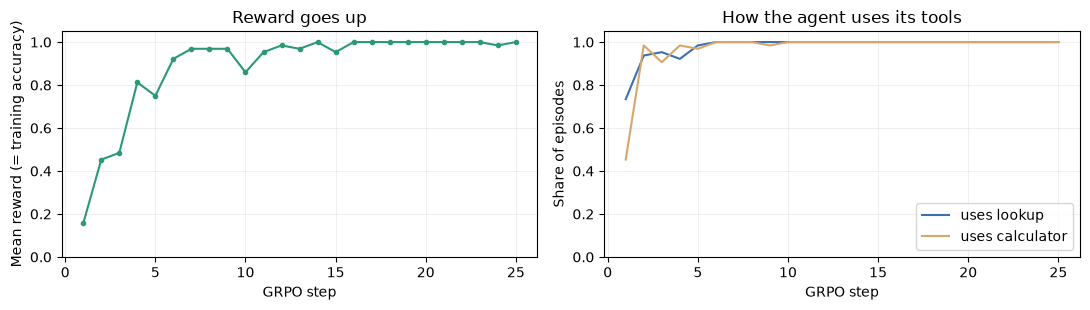

In [26]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.2))
steps = range(1, len(history) + 1)
left.plot(steps, [h["reward"] for h in history], color="#2A9975", marker="o", markersize=3)
left.set(ylim=(0, 1.05), xlabel="GRPO step", ylabel="Mean reward (= training accuracy)",
         title="Reward goes up")
right.plot(steps, [h["lookup_use"] for h in history], label="uses lookup", color="#3B6FB6")
right.plot(steps, [h["calculator_use"] for h in history], label="uses calculator", color="#D7A66B")
right.set(ylim=(0, 1.05), xlabel="GRPO step", ylabel="Share of episodes", title="How the agent uses its tools")
right.legend(loc="lower right")
for ax in (left, right):
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 12 · The big reveal: before vs. after 🏆

The same **64 held-out questions** as before, with greedy decoding.

In [27]:
after = evaluate(model, tokenizer, eval_tasks)
print(f"Before: {before['accuracy']:.0%}  →  After: {after['accuracy']:.0%}\n")
for kind in TASK_KINDS:
    print(f"  {kind:6} {before['per_kind'][kind]:4.0%} → {after['per_kind'][kind]:4.0%}")

Before: 16%  →  After: 100%

  math    64% → 100%
  shop1    6% → 100%
  shop2   13% → 100%
  budget   0% → 100%


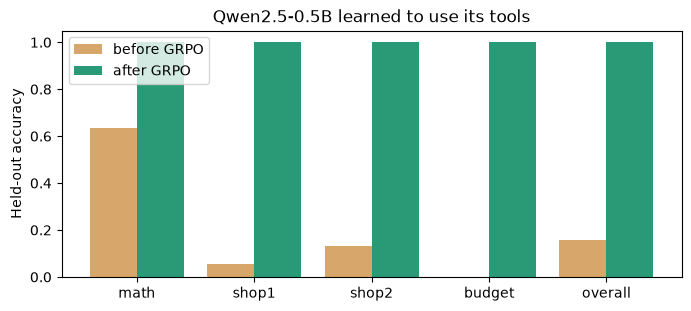

In [28]:
kinds = list(TASK_KINDS) + ["overall"]
b = [before["per_kind"][k] for k in TASK_KINDS] + [before["accuracy"]]
a = [after["per_kind"][k] for k in TASK_KINDS] + [after["accuracy"]]
x = range(len(kinds))
plt.figure(figsize=(8, 3.2))
plt.bar([i - 0.2 for i in x], b, width=0.4, label="before GRPO", color="#D7A66B")
plt.bar([i + 0.2 for i in x], a, width=0.4, label="after GRPO", color="#2A9975")
plt.xticks(list(x), kinds)
plt.ylim(0, 1.05)
plt.ylabel("Held-out accuracy")
plt.title("Qwen2.5-0.5B learned to use its tools")
plt.legend()
plt.show()

### Same question, before and after 🔍

In [29]:
i = next(j for j, t in enumerate(eval_tasks) if t["kind"] == "shop2")
print("Q:", eval_tasks[i]["question"], "  (correct:", eval_tasks[i]["answer"], ")\n")
print("BEFORE GRPO:\n" + before["texts"][i].strip() + "\n")
print("AFTER GRPO:\n" + after["texts"][i].strip())

Q: How much do 15 backpacks and 95 erasers cost in total?   (correct: 499.25 )

BEFORE GRPO:
<lookup>backpack</lookup>
<result>27.90</result>
<lookup>eraser</lookup>

<result>0.85</result>
<answer>28.75</answer>

AFTER GRPO:
<lookup>backpack</lookup>
<result>27.90</result>
<lookup>eraser</lookup>

<result>0.85</result>
<calculator>15 * 27.90 + 95 * 0.85</calculator>
<result>499.25</result>
<answer>499.25</answer>


## 13 · Look closer: did it learn *good* habits? 🕵️

Accuracy isn't the whole story. Let's count **how many tool calls** the agent makes for each kind of question, and look at a pure math question, which needs **no lookup at all**:

In [30]:
from collections import Counter

for kind in TASK_KINDS:
    habits = Counter(" → ".join(calls) for calls, t in zip(after["tool_calls"], eval_tasks) if t["kind"] == kind)
    habit, count = habits.most_common(1)[0]
    print(f"{kind:6} {after['calls_per_kind'][kind]:.1f} tool calls per question | most common: {habit} ({count}x)")

i = next(j for j, t in enumerate(eval_tasks) if t["kind"] == "math")
print("\nA pure math question:", eval_tasks[i]["question"])
print(after["texts"][i].strip())

math   2.1 tool calls per question | most common: lookup → calculator (10x)
shop1  2.0 tool calls per question | most common: lookup → calculator (18x)
shop2  3.0 tool calls per question | most common: lookup → lookup → calculator (15x)
budget 2.0 tool calls per question | most common: lookup → calculator (20x)

A pure math question: A farmer plants 504 rows of trees with 98 trees in each row. How many trees does the farmer plant?
<lookup>tree</lookup>

<result>unknown item</result>
<calculator>504 * 98</calculator>
<result>49392</result>
<answer>49392</answer>


**Plot twist!** Even at 100% accuracy, the agent makes **tool calls it doesn't need**. Look at the pure math question above: it looks up a word like `tree`, gets back `unknown item`, and only *then* calculates.

Why? Our reward only checks the **final answer**. Extra tool calls cost nothing, so RL had no reason to drop them. This is the most important lesson in reward design:

> **RL optimizes exactly what you reward. Nothing more, nothing less.**

The habits also **vary from run to run** (RL is noisy!). Here are three of our training runs, each 25 steps, all at 100% held-out accuracy:

| Tool calls per question | run A, no cost | run B, no cost (this notebook) | run C, `TOOL_COST = 0.02` | fewest possible |
|:--|:-:|:-:|:-:|:-:|
| `math` | 2.8 | 2.1 | 2.0 | 1 |
| `shop1` | 2.7 | 2.0 | 2.0 | 2 |
| `shop2` | 3.0 | 3.0 | 3.0 | 3 |
| `budget` | 3.0 | 2.0 | 2.0 | 2 |

In run A, the agent settled into a full ritual, *lookup → lookup → calculator*, on nearly every question. In every run, including the one with a tool cost, it kept the reflexive lookup before math questions. Old habits die hard!

**The standard fix is something you already know from Chapter 1:** give every tool call a small price (Chapter 1 charged −0.02 for each tool use). Set `TOOL_COST = 0.02` in the training cell and use *Runtime → Restart and run all*. In run C, every shop question was solved with the fewest possible calls, but 25 steps weren't enough to break the math habit.

The cost also made learning **bumpier**. For a few steps, lookup use fell to about 6% and the reward dropped before recovering. Why? Think about a group where **every** attempt got the answer wrong. Without a cost they all score 0, so there's no signal. With a cost, the attempt that used the *fewest* tools scores highest, so GRPO briefly teaches "use fewer tools", which is the opposite of what's needed. Dividing by the group's tiny spread (Chapter 3) turns that tiny difference into a full-strength push. [Dr. GRPO](https://arxiv.org/abs/2503.20783) studies this exact effect.

## 14 · Ask your agent anything (from the shop) 💬

Edit the question and run the cell. Try items that don't exist, or mix in a budget.

In [31]:
my_question = "How much do 25 markers and 40 folders cost in total?"   # 👈 edit me
out = rollout(model, tokenizer, [my_question], greedy=True)
print(out["texts"][0].strip())
print("\nTools used:", out["tool_calls"][0])

<lookup>markers</lookup>
<result>1.65</result>
<lookup>folders</lookup>
<result>0.95</result>
<calculator>25 * 1.65 + 40 * 0.95</calculator>
<result>79.25</result>
<answer>79.25</answer>

Tools used: ['lookup', 'lookup', 'calculator']


Want to keep your trained adapters? They're tiny (~35 MB):

In [32]:
torch.save({n: p.detach().cpu() for n, p in model.named_parameters() if p.requires_grad}, "shop_agent_lora.pt")
print("saved shop_agent_lora.pt")

saved shop_agent_lora.pt


## 15 · What did we actually show? (Honest scope) 🧭

**What this shows:** with a few hundred lines of plain PyTorch, a small open LLM learned **multi-step tool use** (lookup → calculate → answer) from a **0/1 outcome reward**, inside a small simulated shop. We tested it on **held-out** questions.

**What it doesn't show:**

- The questions come from a few templates. A real assistant faces far messier language.
- The tools are tiny and always succeed. Real tools fail, time out, and return long, noisy outputs.
- The agent picked up unnecessary tool calls (section 13), and its habits varied between runs. We report single runs, not averages over many seeds. Real agents need rewards that also value efficiency, safety and cost.
- We trained for minutes, not days, and on one task. We didn't measure whether other skills got worse. That's what the KL leash (`BETA`) is meant to guard against.

These limits are exactly what real agentic-RL systems work hard on, and they make great experiments for you.

## 16 · Your turn: experiments 🧪

1. **Turn on the leash:** set `BETA = 0.04`. Does learning slow down? (It needs an extra forward pass per batch.)
2. **Smaller groups:** set `GROUP_SIZE = 4`. Faster steps, but is the learning as steady?
3. **New stock:** add an item to `PRICES` and ask about it. Does the agent generalize to items it never practiced on?
4. **A new tool:** add a `discount` tool (e.g. "members get 10% off"), mention it in `SYSTEM_PROMPT`, and write questions that need it.
5. **Break the last habit:** with `TOOL_COST = 0.02` the agent still looks something up before every math question. Can you get it to skip that lookup? Try more steps, a bigger cost, or charging only when the answer is correct.
6. **Reward hacking:** change `reward_fn` to also give **+0.5 for every tool call**. Train again and look at the transcripts. What does the agent learn to do? 😈

After changing an earlier cell, use **Runtime → Restart and run all**.

## 17 · Where to go next 🚀

You now understand the core loop used by real agentic-RL systems: **rollouts with tool calls → verifiable reward → group advantages → masked policy-gradient update.** To go bigger:

- **Libraries:** 🤗 [TRL](https://github.com/huggingface/trl) (`GRPOTrainer`) and [verl](https://github.com/volcengine/verl) run the same algorithm at scale, with fast generation engines like vLLM.
- **Papers:** [DeepSeekMath](https://arxiv.org/abs/2402.03300) (introduces GRPO) · [DeepSeek-R1](https://arxiv.org/abs/2501.12948) · [DAPO](https://arxiv.org/abs/2503.14476) · [Dr. GRPO](https://arxiv.org/abs/2503.20783) · [Search-R1](https://arxiv.org/abs/2503.09516) (RL + search tool) · [ReTool](https://arxiv.org/abs/2504.11536) (RL + code interpreter) · [LoRA](https://arxiv.org/abs/2106.09685) · [LoRA Without Regret](https://thinkingmachines.ai/blog/lora/)
- **Bigger models:** swap `MODEL_NAME` for a 1.5B or 3B model on a larger GPU. The code doesn't change.

## 🎓 Congratulations: you trained a tool-using LLM agent with RL!

Across four chapters you built, from scratch:

- ✅ **Ch 1 · Q-learning:** rewards, states, exploration, and planning two steps ahead.
- ✅ **Ch 2 · REINFORCE:** policies, log-probs, and baselines.
- ✅ **Ch 3 · GRPO:** group advantages, clipping, and the KL leash.
- ✅ **Ch 4 · Agentic RL for LLMs:** multi-turn tool rollouts, loss masking, LoRA, and real GRPO training.

**Your one-sentence takeaway:** *An LLM agent learns to use tools the same way our tiny agent learned to press buttons: try, get a reward for the outcome, and make the better attempts more likely.*

⭐ Found this useful? [Star TrainYourAgent on GitHub](https://github.com/HamedKhosravi99/TrainYourAgent) so other beginners can find it.